In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
spam_emails = [
    "Congratulations you won a lottery",
    "Claim your free prize now",
    "You have won a cash reward",
    "Free gift waiting for you",
    "Congratulations claim your bonus",
    "Win a free vacation today",
    "You are selected for a prize",
    "Claim your lottery reward",
    "Get your free cash prize",
    "Special offer claim now",
    "You won a free gift",
    "Congratulations you are a winner",
    "Earn money with this special offer",
    "Free coupon available claim today",
    "Limited time prize offer",
    "Win exciting rewards now",

    "Meeting at 10 AM tomorrow",
    "Project report submission is due",
    "Please attend the department meeting",
    "The class starts at 9 AM",
    "Submit the assignment by Friday",
    "Your project review is scheduled tomorrow",
    "Please send the meeting minutes",
    "The examination timetable is attached",
    "Faculty meeting is scheduled today",
    "Please complete the project report",
    "The seminar begins at 11 AM",
    "Submit your lab record tomorrow",
    "The project presentation is next week",
    "Please attend the academic review",
    "The department meeting is postponed",
    "Assignment submission deadline is Friday"
]

spam_labels = [
    "Spam"] * 16 + ["Not Spam"] * 16

spam_df = pd.DataFrame({
    "email": spam_emails,
    "label": spam_labels
})

spam_df

,email,label
0,Congratulations you won a lottery,Spam
1,Claim your free prize now,Spam
2,You have won a cash reward,Spam
3,Free gift waiting for you,Spam
4,Congratulations claim your bonus,Spam
5,Win a free vacation today,Spam
6,You are selected for a prize,Spam
7,Claim your lottery reward,Spam
8,Get your free cash prize,Spam
9,Special offer claim now,Spam


In [4]:
print("Dataset shape:", spam_df.shape)
print("\nClass distribution:")
print(spam_df["label"].value_counts())

spam_df

Dataset shape: (32, 2)

Class distribution:
label
Spam        16
Not Spam    16
Name: count, dtype: int64


,email,label
0,Congratulations you won a lottery,Spam
1,Claim your free prize now,Spam
2,You have won a cash reward,Spam
3,Free gift waiting for you,Spam
4,Congratulations claim your bonus,Spam
5,Win a free vacation today,Spam
6,You are selected for a prize,Spam
7,Claim your lottery reward,Spam
8,Get your free cash prize,Spam
9,Special offer claim now,Spam


In [5]:
X_text = spam_df["email"]
y = spam_df["label"]

tfidf_spam = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_tfidf = tfidf_spam.fit_transform(X_text)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary size:", len(tfidf_spam.vocabulary_))

TF-IDF matrix shape: (32, 124)
Vocabulary size: 124


In [6]:
feature_names = tfidf_spam.get_feature_names_out()

print("First 30 TF-IDF features:")
print(feature_names[:30])

tfidf_preview = pd.DataFrame(
    X_tfidf.toarray(),
    columns=feature_names
)

tfidf_preview.head()

First 30 TF-IDF features:
['10' '10 tomorrow' '11' 'academic' 'academic review' 'assignment'
 'assignment friday' 'assignment submission' 'attached' 'attend'
 'attend academic' 'attend department' 'available' 'available claim'
 'begins' 'begins 11' 'bonus' 'cash' 'cash prize' 'cash reward' 'claim'
 'claim bonus' 'claim free' 'claim lottery' 'claim today' 'class'
 'class starts' 'complete' 'complete project' 'congratulations']


,10,10 tomorrow,11,academic,academic review,assignment,assignment friday,assignment submission,attached,attend,...,waiting,week,win,win exciting,win free,winner,won,won cash,won free,won lottery
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.402118,0.000000,0.0,0.491735
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.395970,0.484216,0.0,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.497148,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 24
Testing samples : 8


In [8]:
y_pred_nb = nb_model.predict(X_test)

results_nb = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_nb
})

results_nb

NameError: name 'nb_model' is not defined

In [9]:
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print(f"Naïve Bayes Accuracy: {accuracy_nb:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

NameError: name 'y_pred_nb' is not defined

In [10]:
labels_nb = ["Not Spam", "Spam"]

cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=labels_nb
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    xticklabels=labels_nb,
    yticklabels=labels_nb
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Naïve Bayes – Spam Detection Confusion Matrix")
plt.show()

NameError: name 'y_pred_nb' is not defined

In [11]:
new_emails = [
    "Congratulations you have won a free prize",
    "Please submit your project report tomorrow",
    "Claim your cash reward now",
    "The department meeting is at 10 AM"
]

new_email_tfidf = tfidf_spam.transform(new_emails)
new_predictions = nb_model.predict(new_email_tfidf)

new_email_results = pd.DataFrame({
    "New Email": new_emails,
    "Predicted Class": new_predictions
})

new_email_results

NameError: name 'nb_model' is not defined

In [12]:
reviews = [
    "This phone is excellent",
    "The camera quality is amazing",
    "I love this product",
    "The battery life is fantastic",
    "Very good performance and excellent design",
    "This is a wonderful phone",
    "The product works perfectly",
    "I am very happy with this purchase",
    "Excellent quality and great performance",
    "The phone is fast and reliable",

    "Battery performance is poor",
    "The camera quality is terrible",
    "I hate this product",
    "The phone is very slow",
    "Very bad performance",
    "The product stopped working",
    "I am unhappy with this purchase",
    "The quality is disappointing",
    "Poor battery and poor camera",
    "This phone is awful",

    "The product is okay",
    "The phone is average",
    "The camera is acceptable",
    "Battery performance is normal",
    "The product is neither good nor bad",
    "It works as expected",
    "The design is standard",
    "The performance is moderate",
    "The phone is fine",
    "The product is satisfactory"
]

sentiments = (
    ["Positive"] * 10 +
    ["Negative"] * 10 +
    ["Neutral"] * 10
)

review_df = pd.DataFrame({
    "review": reviews,
    "sentiment": sentiments
})

review_df

,review,sentiment
0,This phone is excellent,Positive
1,The camera quality is amazing,Positive
2,I love this product,Positive
3,The battery life is fantastic,Positive
4,Very good performance and excellent design,Positive
5,This is a wonderful phone,Positive
6,The product works perfectly,Positive
7,I am very happy with this purchase,Positive
8,Excellent quality and great performance,Positive
9,The phone is fast and reliable,Positive


In [13]:
print("Dataset shape:", review_df.shape)
print("\nSentiment distribution:")
print(review_df["sentiment"].value_counts())

review_df

Dataset shape: (30, 2)

Sentiment distribution:
sentiment
Positive    10
Negative    10
Neutral     10
Name: count, dtype: int64


,review,sentiment
0,This phone is excellent,Positive
1,The camera quality is amazing,Positive
2,I love this product,Positive
3,The battery life is fantastic,Positive
4,Very good performance and excellent design,Positive
5,This is a wonderful phone,Positive
6,The product works perfectly,Positive
7,I am very happy with this purchase,Positive
8,Excellent quality and great performance,Positive
9,The phone is fast and reliable,Positive


In [14]:
X_review_text = review_df["review"]
y_review = review_df["sentiment"]

tfidf_review = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_review_tfidf = tfidf_review.fit_transform(X_review_text)

print("TF-IDF matrix shape:", X_review_tfidf.shape)
print("Vocabulary size:", len(tfidf_review.vocabulary_))

TF-IDF matrix shape: (30, 83)
Vocabulary size: 83


In [15]:
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(
    X_review_tfidf,
    y_review,
    test_size=0.30,
    random_state=42,
    stratify=y_review
)

print("Training samples:", X_train_svm.shape[0])
print("Testing samples :", X_test_svm.shape[0])

Training samples: 21
Testing samples : 9


In [16]:
svm_model = LinearSVC(C=1.0, random_state=42)
svm_model.fit(X_train_svm, y_train_svm)

print("SVM model trained successfully.")

SVM model trained successfully.


In [17]:
y_pred_svm = svm_model.predict(X_test_svm)

results_svm = pd.DataFrame({
    "Actual": y_test_svm.values,
    "Predicted": y_pred_svm
})

results_svm

,Actual,Predicted
0,Negative,Neutral
1,Positive,Neutral
2,Positive,Negative
3,Neutral,Neutral
4,Negative,Positive
5,Neutral,Negative
6,Positive,Neutral
7,Negative,Neutral
8,Neutral,Neutral


In [18]:
accuracy_svm = accuracy_score(y_test_svm, y_pred_svm)

print(f"SVM Accuracy: {accuracy_svm:.2%}")
print("\nClassification Report:")
print(classification_report(y_test_svm, y_pred_svm))

SVM Accuracy: 22.22%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         3
     Neutral       0.33      0.67      0.44         3
    Positive       0.00      0.00      0.00         3

    accuracy                           0.22         9
   macro avg       0.11      0.22      0.15         9
weighted avg       0.11      0.22      0.15         9



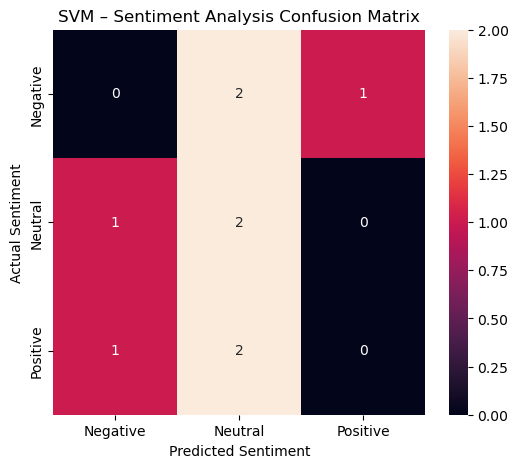

In [19]:
labels_svm = ["Negative", "Neutral", "Positive"]

cm_svm = confusion_matrix(
    y_test_svm,
    y_pred_svm,
    labels=labels_svm
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    xticklabels=labels_svm,
    yticklabels=labels_svm
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("SVM – Sentiment Analysis Confusion Matrix")
plt.show()

In [20]:
new_reviews = [
    "The phone has excellent performance",
    "The battery is very poor",
    "The product is average and acceptable",
    "I am extremely happy with the phone",
    "The camera quality is terrible"
]

new_review_tfidf = tfidf_review.transform(new_reviews)
new_predictions_svm = svm_model.predict(new_review_tfidf)

new_review_results = pd.DataFrame({
    "New Review": new_reviews,
    "Predicted Sentiment": new_predictions_svm
})

new_review_results

,New Review,Predicted Sentiment
0,The phone has excellent performance,Positive
1,The battery is very poor,Negative
2,The product is average and acceptable,Neutral
3,I am extremely happy with the phone,Positive
4,The camera quality is terrible,Negative
